# 01 · Calidad de datos y unidad de análisis

**Proyecto IND2622 — consumo eléctrico del mercado cativo (ANEEL/SAMP)**

Este notebook responde a la primera crítica del proyecto anterior: *no estaba claro
qué representaba cada fila ni qué se estaba sumando*. El recorrido es:

1. Qué contiene el archivo crudo y qué significa cada columna.
2. Por qué `VlrMercado` **no es una sola variable** y cómo se separa por unidad.
3. Qué filtros se aplican y cuántas filas sobreviven a cada uno.
4. Cuál es la unidad de análisis y por qué es el segmento distribuidora × clase.
5. Qué se excluye y qué porcentaje del consumo queda representado.

## 1. Entorno y fuentes

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

from src import config as C

print("Raiz del proyecto:", RAIZ)
print("Ventana:", C.MES_INICIO, "a", C.MES_FIN, f"({C.N_MESES} meses)")

Raiz del proyecto: C:\Users\yennz\OneDrive\Documentos\Ciencia de Datos
Ventana: 2021-01 a 2026-08 (68 meses)


In [2]:
archivos = sorted(C.RAW_DIR.glob("samp-*.csv"))
pd.DataFrame({
    "archivo": [p.name for p in archivos],
    "MB": [round(p.stat().st_size / 1e6, 1) for p in archivos],
})

,archivo,MB
0,samp-2021.csv,263.1
1,samp-2022.csv,270.2
2,samp-2023.csv,311.1
3,samp-2024.csv,369.3
4,samp-2025.csv,389.2
5,samp-2026.csv,274.2


In [3]:
crudo = pd.read_csv(archivos[3], sep=";", encoding="latin1", nrows=6, dtype=str)
print("Columnas:", len(crudo.columns))
crudo.iloc[:3, :9]

Columnas: 18


,DatGeracaoConjuntoDados,NumCNPJAgenteDistribuidora,SigAgenteDistribuidora,NomAgenteDistribuidora,NomTipoMercado,DscModalidadeTarifaria,DscSubGrupoTarifario,DscClasseConsumoMercado,DscSubClasseConsumidor
0,2026-10-15,10835932000108,Neoenergia PE,COMPANHIA ENERGETICA DE PERNAMBUCO,Refaturamento - Regular,Azul,A4,Comercial,Não se aplica
1,2026-10-15,10835932000108,Neoenergia PE,COMPANHIA ENERGETICA DE PERNAMBUCO,Regular,Branca,B2,Rural,Agropecuária rural
2,2026-10-15,10835932000108,Neoenergia PE,COMPANHIA ENERGETICA DE PERNAMBUCO,Regular,Convencional,B1,Residencial,Residencial baixa renda  faixa 01


El archivo es un panel **largo**: cada fila es una combinación de
`DatCompetencia` × `SigAgenteDistribuidora` × `DscClasseConsumoMercado` ×
`NomTipoMercado` × `DscOpcaoEnergia` × `DscDetalheMercado`.

La columna `VlrMercado` contiene **todos** los conceptos del mercado, no solo
consumo. El significado depende de `DscDetalheMercado`.

## 2. La trampa de `VlrMercado`

`DscDetalheMercado` mezcla magnitudes físicas y monetarias. La tabla siguiente se
calcula sobre el archivo 2024 completo, agregando por detalle:

- `unidad` se infiere del nombre del detalle (R$, kWh, kW, %, conteo).
- `filas`, `media` y `maximo` muestran el orden de magnitud de cada concepto.

In [4]:
from collections import defaultdict
from src.aneel_pipeline import parse_br

def unidad_de(detalle: str) -> str:
    if detalle.lower().startswith("número de consum"):
        return "conteo"
    if detalle.endswith("(%)"):
        return "%"
    if "(R$)" in detalle:
        return "R$"
    if "(kWh)" in detalle:
        return "kWh"
    if "(kW)" in detalle:
        return "kW"
    return "otra"

acc = defaultdict(lambda: [0, 0.0, 0.0])
ruta2024 = C.RAW_DIR / "samp-2024.csv"
for ch in pd.read_csv(ruta2024, sep=";", encoding="latin1", dtype=str,
                      usecols=["DscDetalheMercado", "VlrMercado"],
                      chunksize=250_000, low_memory=False):
    ch["valor"] = parse_br(ch["VlrMercado"])
    for det, g in ch.groupby("DscDetalheMercado"):
        a = acc[det]
        a[0] += len(g)
        a[1] += float(g["valor"].sum())
        a[2] = max(a[2], float(g["valor"].max()))

detalles = pd.DataFrame(
    [{"detalle": d, "unidad": unidad_de(d), "filas": v[0],
      "media": v[1] / v[0] if v[0] else np.nan, "maximo": v[2]}
     for d, v in acc.items()]
).sort_values("filas", ascending=False)
detalles.head(14).style.format({"filas": "{:,.0f}", "media": "{:,.1f}", "maximo": "{:,.1f}"})

,detalle,unidad,filas,media,maximo
21,Receita Energia (R$),R$,"140,650","1,549,895.6","919,153,796.2"
10,Energia TUSD (kWh),kWh,"137,123","3,597,196.4","1,318,783,997.0"
9,Energia TE (kWh),kWh,"125,030","2,445,830.3","1,318,783,997.0"
13,ICMS (R$),R$,"85,653","639,826.1","958,809,836.0"
15,Número de consumidores,conteo,"78,894","14,158.0","6,360,817.0"
0,COFINS (R$),R$,"74,403","120,506.6","108,697,613.0"
17,PIS/PASEP (R$),R$,"74,176","26,118.8","23,682,714.0"
2,Demanda Faturada (kW),kW,"66,529","22,702.0","25,234,333.0"
20,Receita Demanda (R$),R$,"66,216","333,719.2","967,484,314.0"
7,Energia Consumida (kWh),kWh,"57,922","890,870.6","267,134,232.0"


In [5]:
resumen_unidades = (detalles.groupby("unidad")
                    .agg(detalles=("detalle", "nunique"), filas=("filas", "sum"))
                    .sort_values("filas", ascending=False))
resumen_unidades["filas_pct"] = 100 * resumen_unidades["filas"] / resumen_unidades["filas"].sum()
resumen_unidades.round(1)

,detalles,filas,filas_pct
unidad,,,
R$,9,560129,43.0
kWh,7,438861,33.7
otra,5,105857,8.1
conteo,2,105790,8.1
kW,2,92810,7.1


**Lectura.** En 2024 hay ~1,1 millones de filas repartidas en R$, kWh, kW, % y
conteos. Sumar `VlrMercado` sin separar produce un número sin significado: se
estarían sumando ingresos con energía, demanda y porcentajes. Ese fue el origen
del silhouette = 0,89 del trabajo anterior: un artefacto, no un hallazgo.

**Regla del proyecto.** Para consumo se usa **solo** `Energia TUSD (kWh)`.
`Energia TE (kWh)` contiene exactamente el mismo consumo (es el mismo kWh
facturado, separado en dos componentes tarifarios); sumarlas lo duplicaría.
Los R$, kW, % y conteos se excluyen del análisis de consumo y se usan solo como
variables de contexto.

## 3. Filtros y construcción del panel

La siguiente tabla reconstruye el embudo de filas con las cifras reales del
pipeline (`data/processed/calidad_panel.json`).

In [6]:
import json
calidad = json.loads((C.PROCESSED_DIR / "calidad_panel.json").read_text(encoding="utf-8"))
embudo = pd.DataFrame([
    ("Filas crudas leídas (6 CSV)", calidad["filas_leidas"]),
    ("Mercado Regular + CATIVO", calidad["filas_regular_cativo"]),
    ("... con detalle Energia TUSD (kWh)", calidad["filas_energia_tusd"]),
    ("... con detalle Número de consumidores", calidad["filas_num_consumidores"]),
    ("Filas del panel unidad × mes (crudo)", calidad["filas_panel"]),
])
embudo.columns = ["etapa", "filas"]
embudo["pct_del_crudo"] = (100 * embudo["filas"] / calidad["filas_leidas"]).round(2)
embudo.style.format({"filas": "{:,.0f}", "pct_del_crudo": "{:.2f}%"})

,etapa,filas,pct_del_crudo
0,Filas crudas leídas (6 CSV),"6,671,150",100.00%
1,Mercado Regular + CATIVO,"2,116,425",31.73%
2,... con detalle Energia TUSD (kWh),"302,717",4.54%
3,... con detalle Número de consumidores,"180,989",2.71%
4,Filas del panel unidad × mes (crudo),"55,140",0.83%


In [7]:
panel = pd.read_csv(C.PROCESSED_DIR / "painel_mensal.csv")
print("Panel:", panel.shape)
print("Unidades:", panel["unidad"].nunique(), "| agentes:", panel["agente"].nunique())
print("Meses:", panel["mes"].min(), "a", panel["mes"].max())
panel.head()

Panel: (55140, 6)
Unidades: 833 | agentes: 105
Meses: 2021-01 a 2026-09


,unidad,agente,clase,mes,consumo_mwh,n_consumidores
0,CASTRO-DIS | Comercial,CASTRO-DIS,Comercial,2021-01,176.083,99.0
1,CASTRO-DIS | Comercial,CASTRO-DIS,Comercial,2021-02,170.662,98.0
2,CASTRO-DIS | Comercial,CASTRO-DIS,Comercial,2021-03,166.843,103.0
3,CASTRO-DIS | Comercial,CASTRO-DIS,Comercial,2021-04,168.165,117.0
4,CASTRO-DIS | Comercial,CASTRO-DIS,Comercial,2021-05,169.957,115.0


## 4. Unidad de análisis y cobertura

La unidad es:

> **segmento de mercado = distribuidora (`SigAgenteDistribuidora`) × clase de consumo (`DscClasseConsumoMercado`)**

No es un consumidor individual: ANEEL publica el agregado mensual por clase
dentro de cada distribuidora. Es la unidad sobre la que efectivamente se decide
(tarifa, metas, priorización comercial), y es la más fina que los datos permiten.

Para que una unidad entre al clustering se exige **cobertura temporal ≥ 95 %**
(≥ 65 de 68 meses) y capacidad de imputar huecos internos de hasta 2 meses. La
cobertura se mide **antes** de imputar; por eso las 700 unidades incluidas
terminan con serie completa.

In [8]:
meta = pd.read_csv(C.PROCESSED_DIR / "unidades_meta.csv", index_col=0)
resumen_cob = (meta.groupby(["incluida", "motivo_exclusion"])
               .agg(unidades=("cobertura", "size"), mwh=("total_mwh", "sum")))
resumen_cob["mwh_twh"] = (resumen_cob["mwh"] / 1e6).round(1)
resumen_cob[["unidades", "mwh_twh"]]

,,unidades,mwh_twh
incluida,motivo_exclusion,,
False,cobertura temporal insuficiente,34,10.2


In [9]:
incl = meta[meta["incluida"]]
print(f"Unidades incluidas: {len(incl)} de {len(meta)} ({100*len(incl)/len(meta):.1f}%)")
print(f"Consumo incluido: {incl['total_mwh'].sum()/1e6:,.1f} TWh")
print(f"Cobertura media de las incluidas: {incl['cobertura'].mean():.3f}")
print(f"Consumo por unidad: mediana {incl['total_mwh'].median():,.0f} MWh; "
      f"maximo {incl['total_mwh'].max():,.0f} MWh")

Unidades incluidas: 700 de 734 (95.4%)
Consumo incluido: 1,587.2 TWh
Cobertura media de las incluidas: 1.000
Consumo por unidad: mediana 69,217 MWh; maximo 98,086,170 MWh


In [10]:
top = (incl.sort_values("total_mwh", ascending=False)
       .head(12)[["agente", "clase", "total_mwh", "cobertura", "cv"]]
       .assign(total_twh=lambda d: (d["total_mwh"] / 1e6).round(2))
       .drop(columns="total_mwh"))
top

,agente,clase,cobertura,cv,total_twh
unidad,,,,,
ELETROPAULO | Residencial,ELETROPAULO,Residencial,1.0,0.051773,98.09
CEMIG-D | Residencial,CEMIG-D,Residencial,1.0,0.066625,66.70
CPFL-PAULISTA | Residencial,CPFL-PAULISTA,Residencial,1.0,0.097870,58.60
COPEL-DIS | Residencial,COPEL-DIS,Residencial,1.0,0.091167,47.48
LIGHT SESA | Residencial,LIGHT SESA,Residencial,1.0,0.145527,46.01
COELBA | Residencial,COELBA,Residencial,1.0,0.066180,43.55
ELETROPAULO | Comercial,ELETROPAULO,Comercial,1.0,0.092956,42.32
CELESC | Residencial,CELESC,Residencial,1.0,0.154188,41.08
EQUATORIAL GO | Residencial,EQUATORIAL GO,Residencial,1.0,0.094726,33.22


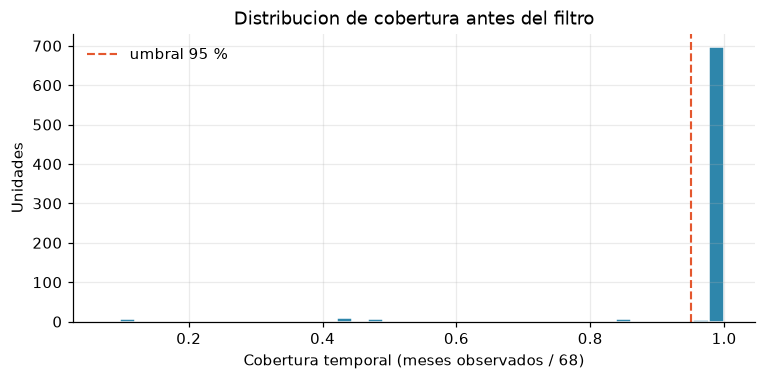

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(meta["cobertura"], bins=40, color="#2E86AB", edgecolor="white")
ax.axvline(0.95, color="#E4572E", ls="--", lw=1.4, label="umbral 95 %")
ax.set_xlabel("Cobertura temporal (meses observados / 68)")
ax.set_ylabel("Unidades")
ax.set_title("Distribucion de cobertura antes del filtro")
ax.legend(frameon=False)
plt.show()

**Resultado.** De las 833 unidades del panel, 99 corresponden a clases que no son
mercado atendido (`No se aplica`, `Consumo propio`) y se descartan. Quedan 734
segmentos analizables; **700** cumplen cobertura y concentran el **99,4 %** del
consumo de esas clases. Los 34 restantes son segmentos pequeños o intermitentes
(10,2 TWh, 0,6 %); excluirlos evita imputar series que no existen.

La figura `01_cobertura_temporal.png` muestra el consumo mensual agregado; la
caída de 2026-09 es el mes parcial del corte de datos (2,4 TWh frente a ~20 TWh
de un mes completo) y por eso se excluye de la ventana.

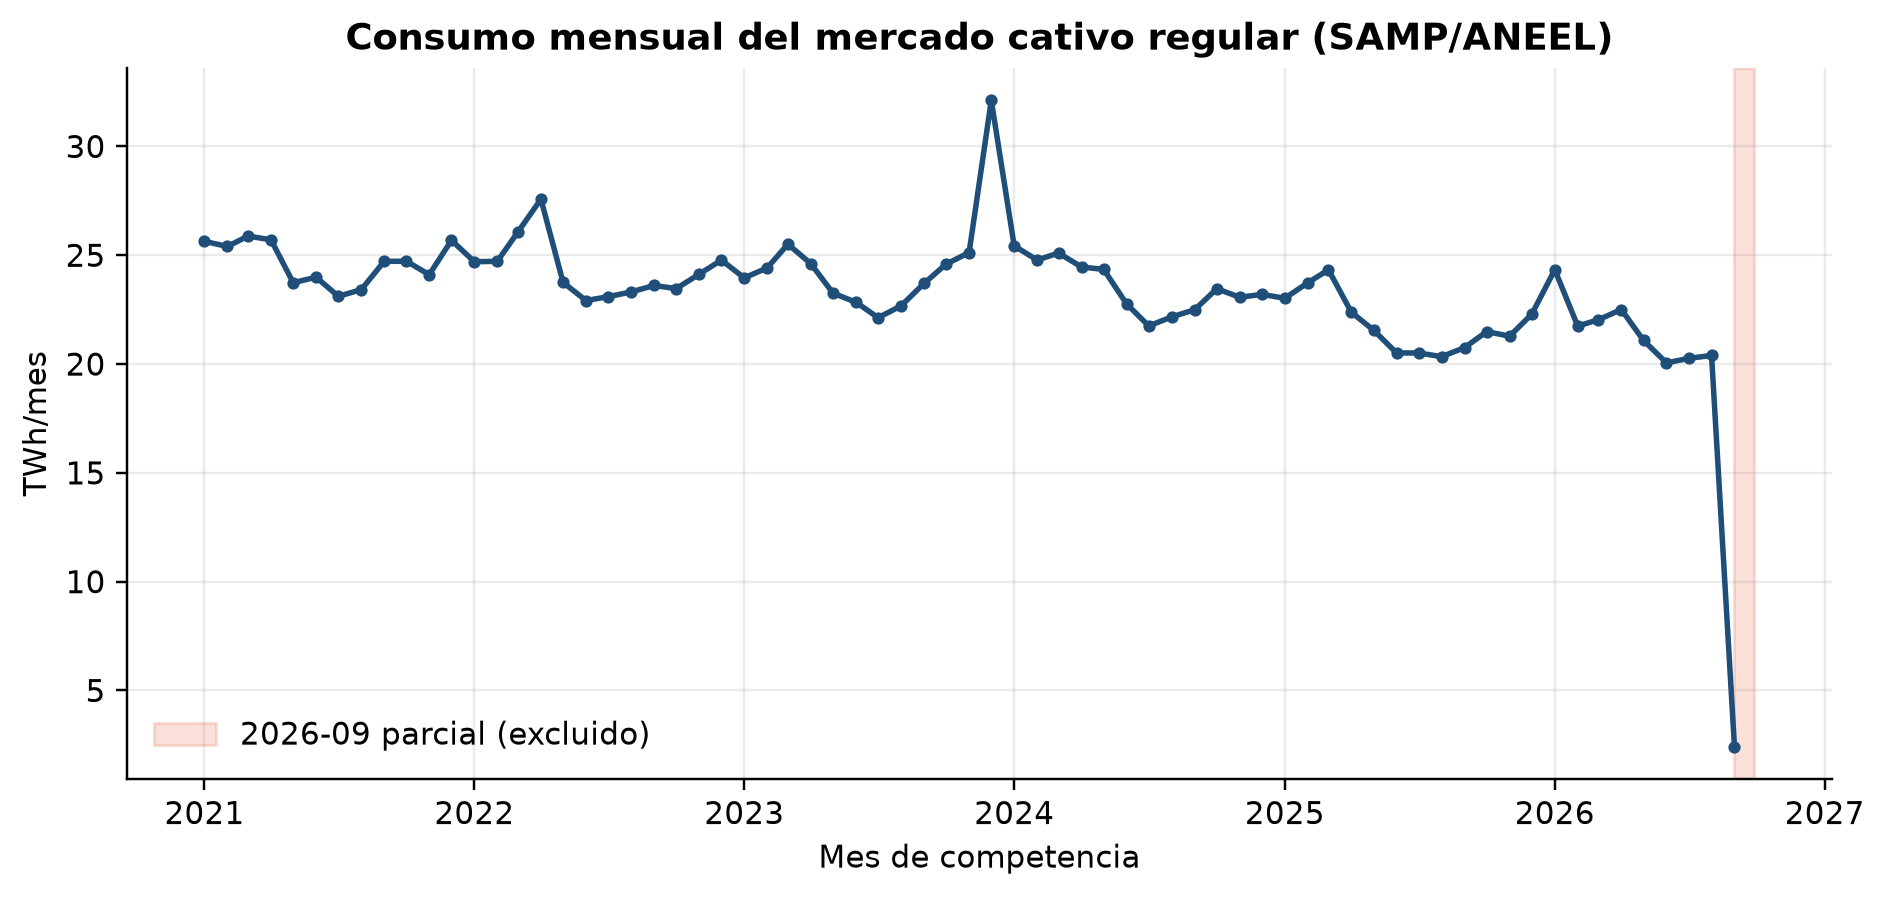

In [12]:
from IPython.display import Image, display
display(Image(filename=str(C.FIGURES_DIR / "01_cobertura_temporal.png"), width=820))

## 5. Hallazgos de calidad que hay que poder defender

| Hallazgo | Evidencia | Decisión |
|---|---|---|
| `VlrMercado` mezcla unidades | 5 unidades distintas en `DscDetalheMercado` | Analizar solo `Energia TUSD (kWh)` |
| TE y TUSD son el mismo kWh | correlación 1,0 y mismos totales | Nunca sumar ambas |
| 10 % de valores negativos | 664.448 filas, todas en R$ (ajustes/refacturación) | No afectan energía: 0 negativos en kWh |
| Formatos numéricos brasileños | 100 % con coma decimal; 54.767 con formato inválido | `parse_br` + coerción a NaN |
| Cardinalidad de texto | `Serviço Público` vs `Serviço público` | Mapa explícito de clases |
| Mes parcial al final | 2026-09 con 2,4 TWh | Excluir 2026-09 |
| Caso sensible en detalles | `Número de Consumidores` (otros mercados) vs `Número de consumidores` (CATIVO) | No normalizar mayúsculas en `DscDetalheMercado` |

Los dos últimos puntos son importantes: normalizar todo a minúsculas habría
mezclado consumidores del mercado libre con los del cativo y habría inflado el
conteo. El filtro `Regular + CATIVO` se aplica **antes** de agregar.